# Graph clustering of Amazon books: reader communities for long-tail recommendations

**02807 Computational Tools for Data Science - final project, graph-clustering part.**

Question: do reader communities found by graph clustering (on graphs of co-readers, co-liked books and,
when available, review-text similarity) recommend long-tail books better than purchase overlap alone?

This notebook runs the whole graph-clustering part end to end:

1. preprocessing (shared with the group): time split, iterative k-core, "liked" flag
2. sparse user x book matrix
3. book-book graphs via sparse products (co-reader, co-liked, external edge lists)
4. edge weighting - raw counts, Jaccard, PPMI (**implemented by us**)
5. sparsification - disparity-filter backbone and top-k baseline (**implemented by us**)
6. clustering - Louvain (library, resolution and seed sweep) and spectral clustering (**implemented by us**)
7. community evaluation - modularity (**ours**, checked against libraries), sizes, NMI vs genres, mixed-genre communities
8. community-based recommender vs "most popular" and "readers also bought" baselines, by popularity group

Reusable code lives in `src/ctds/graph/` (small functions with docstrings); the notebook only orchestrates
and explains. Design decisions and their reasons: `docs/graph_clustering_decisions.md`.

### How to run

1. Put the data next to the repo: `../data/books_50pct/books_50pct_users_reviews.parquet` and
   `books_50pct_users_meta.parquet` (unzip `books_50pct.zip`), or set `CTDS_DATA_DIR`.
2. `uv sync` in the repo, then open this notebook with the project's kernel.
3. Run with `SAMPLE = True` first (15% of users, a few minutes), then `SAMPLE = False` for the full
   data (~35 min on a 16 GB MacBook, peak memory ~3.2 GB). From a terminal:
   `CTDS_SAMPLE=0 uv run jupyter nbconvert --to notebook --execute --inplace notebooks/graph_clustering.ipynb`
4. Tables are written to `docs/results/<run>/`, figures to `docs/figures/<run>/`. Intermediate data is
   cached as Parquet / npz in `../data/cache/graph/<run>/` (never in the repo).

In [1]:
import os, sys, json, time, warnings
from pathlib import Path

REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(REPO / "src"))  # also works when macOS hides the venv's .pth file

import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from IPython.display import display

from ctds.graph.config import Config, sample_config
from ctds.graph.data import prepare
from ctds.graph.matrix import Bipartite, build_bipartite
from ctds.graph.metadata import load_book_metadata
from ctds.graph.build import cooccurrence_graph, graph_from_edge_list, user_weights
from ctds.graph.weights import apply_weighting
from ctds.graph.sparsify import (alpha_sweep, backbone_stats, disparity_alpha_for_edges, disparity_filter,
                                 giant_component, top_k_neighbours)
from ctds.graph.cluster import (louvain, modularity, networkx_modularity, resolution_sweep, spectral_clustering,
                                spectral_embedding, summarise_sweep, to_igraph)
from ctds.graph.evaluate import community_genre_table, community_sizes, genre_nmi, size_summary
from ctds.graph.recommend import (CommunityRecommender, HybridRecommender, ItemKNNRecommender, PopularityRecommender,
                                  book_popularity, evaluate, make_test_set, paired_bootstrap, popularity_groups,
                                  series_onehot, split_test_users)
from ctds.graph.utils import process_peak_rss_gb, runtime_table, timed
from ctds.graph import plotting as P

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.precision", 4)
P.set_style()

# ---- main switch -------------------------------------------------------------------------------
SAMPLE = os.environ.get("CTDS_SAMPLE", "1") == "1"   # True: quick sample run; False: full data
SEED = 42
cfg = sample_config(seed=SEED) if SAMPLE else Config(seed=SEED)

RUN = cfg.tag
RESULTS = REPO / "docs" / "results" / RUN; RESULTS.mkdir(parents=True, exist_ok=True)
FIGS = REPO / "docs" / "figures" / RUN; FIGS.mkdir(parents=True, exist_ok=True)
SUMMARY = {"run": RUN, "config": cfg.as_dict()}   # headline numbers, saved as JSON at the end

def save_table(df, name):
    df.to_csv(RESULTS / f"{name}.csv", index=False)
    return df

print("run:", RUN); print("data:", cfg.data_dir); print("cache:", cfg.run_dir)

run: full_fromall_cut2014-01-01_u5b15
data: /Users/vishwaa/Documents/DTU/computational Tools for data science/data/books_50pct
cache: /Users/vishwaa/Documents/DTU/computational Tools for data science/data/cache/graph/full_fromall_cut2014-01-01_u5b15


In [2]:
# ---- parameters of the graph-clustering part ---------------------------------------------------
SOURCES = {"co-reader": "read", "co-liked": "liked"}   # which user x book matrix each graph comes from
WEIGHTINGS = ["raw", "jaccard", "ppmi"]
USER_WEIGHTING = "log"        # 1/log(1+d_u) down-weighting of heavy users (see build.user_weights)
MIN_SHARED = 2                # keep an edge only if >= 2 users are shared
TOP_K = 10                    # top-k baseline; the disparity backbone is matched to its edge budget
ALPHAS = [0.3, 0.1, 0.05, 0.01]
RESOLUTIONS = [0.5, 1, 2, 5, 10, 20]
SEEDS = [0, 1, 2, 3, 4]
MAIN = ("co-liked", "jaccard", "disparity")   # variant used for the detailed clustering analysis
SPECTRAL_KS = [20, 40, 60]
TEXT_GRAPH_PATH = None        # teammate's LSH/SBERT edge list (Parquet: book_a, book_b, weight), when it exists
K = 10                        # top-10 recommendations

## 1. Preprocessing (shared with the group)

The data is a user-based pull of ~50% of Amazon Books reviewers with **all** their book reviews (Amazon 2014
release, reviews 1996 - July 2014; see the decisions document). Agreed preprocessing:

- all years; **cut-off 2014-01-01** - graphs are built from earlier reviews, Jan-Jul 2014 is the test period
- **iterative k-core**: users >= 5 reviews and books >= 15 reviews, repeated until both hold (sample run: books >= 10)
- **liked** = rating >= 4 (and, once the sentiment column exists, sentiment not negative)
- optional duplicate-edition mapping from the LSH part (identity until it exists)

In [3]:
with timed("1 preprocessing"):
    data = prepare(cfg)
train, test, kcore_log = data["train"], data["test"], data["kcore_log"]
display(save_table(kcore_log, "kcore_log"))

split = pd.DataFrame({
    "part": ["train (< cut-off)", "test (>= cut-off)"],
    "reviews": [len(train), len(test)],
    "users": [train.user_id.nunique(), test.user_id.nunique()],
    "books": [train.item_id.nunique(), test.item_id.nunique()],
    "liked_pct": [100 * train.liked.mean(), 100 * test.liked.mean()],
})
display(save_table(split, "train_test_split"))
SUMMARY["kcore"] = kcore_log.iloc[-1][["reviews", "users", "books"]].astype(int).to_dict()
SUMMARY["kcore_iterations"] = int(kcore_log.iteration.max())

loading cached preprocessing from /Users/vishwaa/Documents/DTU/computational Tools for data science/data/cache/graph/full_fromall_cut2014-01-01_u5b15
[1 preprocessing] 0.1s, heap peak 0.00 GB, process peak RSS 0.51 GB


,iteration,step,reviews_removed,users_removed,books_removed,reviews,users,books
0,0,start,0,0,0,4408904,301553,349741
1,1,drop users < 5,5167,1301,3,4403737,300252,349738
2,1,drop books < 15,1572279,6821,284772,2831458,293431,64966
3,2,drop users < 5,318029,110604,3,2513429,182827,64963
4,2,drop books < 15,128296,40,10612,2385133,182787,54351
5,3,drop users < 5,50435,13639,0,2334698,169148,54351
6,3,drop books < 15,23993,1,1782,2310705,169147,52569
7,4,drop users < 5,11085,2841,0,2299620,166306,52569
8,4,drop books < 15,5048,0,367,2294572,166306,52202
9,5,drop users < 5,2482,627,0,2292090,165679,52202


,part,reviews,users,books,liked_pct
0,train (< cut-off),1738308,155442,47937,79.6202
1,test (>= cut-off),548879,102580,44093,83.7363


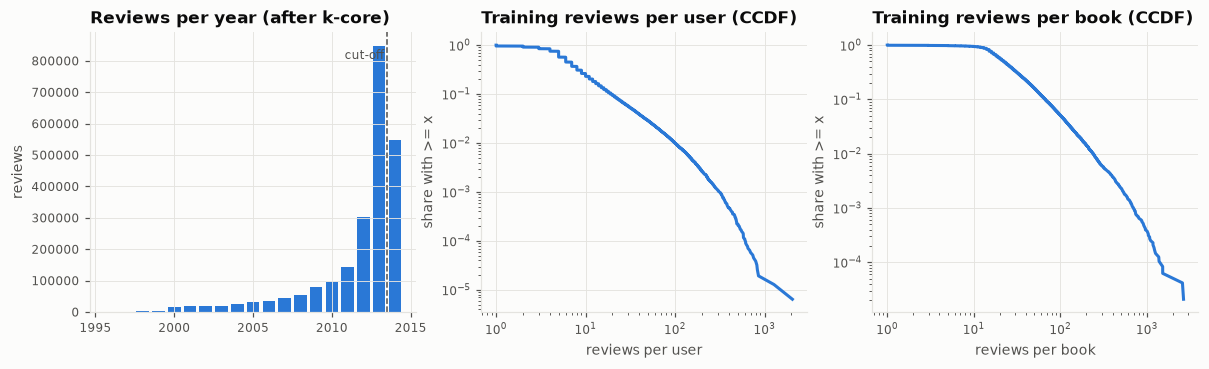

In [4]:
both = pd.concat([train, test])
years = pd.to_datetime(both.timestamp, unit="s").dt.year.value_counts().sort_index()
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
axes[0].bar(years.index, years.values, color=P.PALETTE[0], width=0.8)
axes[0].axvline(2013.5, color=P.TEXT_2, lw=1, ls="--"); axes[0].text(2013.3, years.max() * 0.95, "cut-off", ha="right", color=P.TEXT_2, fontsize=8)
axes[0].set_title("Reviews per year (after k-core)"); axes[0].set_ylabel("reviews")
for ax, col, name in [(axes[1], "user_id", "user"), (axes[2], "item_id", "book")]:
    counts = train[col].value_counts().to_numpy()
    x = np.sort(counts); ccdf = 1 - np.arange(len(x)) / len(x)
    ax.loglog(x, ccdf, color=P.PALETTE[0])
    ax.set_title(f"Training reviews per {name} (CCDF)"); ax.set_xlabel(f"reviews per {name}"); ax.set_ylabel("share with >= x")
P.save(fig, FIGS, "01_data_distributions"); plt.show()

## 2. Sparse user x book matrix

Two CSR matrices from the training reviews: `read` (1 if the user reviewed the book) and `liked`
(1 if the review counts as liked). Integer index mappings are saved next to them so other parts can reuse them.

In [5]:
with timed("2 bipartite matrix"):
    bp = build_bipartite(train)
    bp.save(cfg.run_dir)
meta = load_book_metadata(cfg, bp.book_ids)            # row i = book i
info = {"users": bp.n_users, "books": bp.n_books, "read_nnz": bp.read.nnz, "liked_nnz": bp.liked.nnz,
        "density_pct": 100 * bp.read.nnz / (bp.n_users * bp.n_books),
        "books_with_genre": int(meta.primary_genre.notna().sum()), "books_with_series": int(meta.series.notna().sum())}
display(pd.DataFrame([info]))
SUMMARY["bipartite"] = info

[2 bipartite matrix] 5.0s, heap peak 0.20 GB, process peak RSS 0.91 GB


,users,books,read_nnz,liked_nnz,density_pct,books_with_genre,books_with_series
0,155442,47937,1738308,1384044,0.0233,7489,6899


## 3. Book-book graphs via sparse products

The co-occurrence graph is $C = B^\top W B$ for the user x book matrix $B$ (`read` -> **co-reader** graph, `liked` ->
**co-liked** graph: only readers who liked *both* books count). It is computed in blocks of books and
thresholded per block, so no dense all-pairs matrix is ever formed.

**Heavy users.** A user with $d$ books adds $d(d-1)/2$ pairs, so a few heavy reviewers would dominate the edge
weights. Each user is weighted by $w_u = 1/\log(1+d_u)$ (like inverse document frequency / Adamic-Adar): heavy users
stay in the graph but count less. After the k-core the heaviest training user has ~2k books, so the product fits
in memory without a cap (`max_user_books` exists for other settings). We also require >= 2 shared users per edge.

In [6]:
deg = np.diff(bp.read.indptr)
pairs = deg * (deg - 1) / 2
heavy = deg > 500
print(f"max books per user {deg.max()}, users > 500 books: {heavy.sum()} ({100 * heavy.mean():.2f}%), "
      f"share of co-occurrence pairs they create: {100 * pairs[heavy].sum() / pairs.sum():.1f}%")
w = user_weights(deg)
print(f"weight of a median user ({int(np.median(deg))} books): {1 / np.log1p(np.median(deg)):.3f}; of the heaviest: {w.min():.3f}")
SUMMARY["heavy_users"] = {"max_degree": int(deg.max()), "users_gt500": int(heavy.sum()),
                          "pair_share_gt500_pct": round(float(100 * pairs[heavy].sum() / pairs.sum()), 1)}

cographs = {}
for name, matrix in SOURCES.items():
    with timed(f"3 graph {name}"):
        cographs[name] = cooccurrence_graph(getattr(bp, matrix), user_weighting=USER_WEIGHTING,
                                            min_shared=MIN_SHARED, seed=SEED, name=name)
graph_table = pd.DataFrame([{"graph": n, "nodes": g.weights.shape[0], "edges": g.n_edges,
                             "isolated_books": int((np.diff(g.weights.indptr) == 0).sum()),
                             "mean_degree": g.weights.nnz / g.weights.shape[0]} for n, g in cographs.items()])
display(save_table(graph_table, "cooccurrence_graphs"))

max books per user 2049, users > 500 books: 34 (0.02%), share of co-occurrence pairs they create: 17.5%
weight of a median user (6 books): 0.514; of the heaviest: 0.131


[3 graph co-reader] 6.2s, heap peak 0.94 GB, process peak RSS 2.86 GB


[3 graph co-liked] 3.9s, heap peak 0.56 GB, process peak RSS 2.96 GB


,graph,nodes,edges,isolated_books,mean_degree
0,co-reader,47937,6951673,711,290.0337
1,co-liked,47937,4043544,1312,168.7024


**External graphs (review text).** The LSH / SBERT teammate's review-text similarity graph enters through
`graph_from_edge_list`: any `(book_a, book_b, weight)` table is mapped to our book index (optionally through the
canonical-edition map) and then goes through exactly the same sparsification, clustering and evaluation.
Until that file exists we check the adapter by round-tripping one of our own graphs through an edge list.

In [7]:
U = sp.triu(cographs["co-liked"].weights, k=1).tocoo()
edge_list = pd.DataFrame({"book_a": bp.book_ids[U.row], "book_b": bp.book_ids[U.col], "weight": U.data})
roundtrip, report = graph_from_edge_list(edge_list, bp.book_ids)
print("adapter report:", report, "| identical to the original:", abs(roundtrip - cographs["co-liked"].weights).max() < 1e-6)

external = {}
if TEXT_GRAPH_PATH and Path(TEXT_GRAPH_PATH).exists():
    G_text, report = graph_from_edge_list(pd.read_parquet(TEXT_GRAPH_PATH), bp.book_ids)
    print("text graph:", report)
    external["text"] = G_text

adapter report: {'input_edges': 4043544, 'unknown_book_edges': 0, 'self_loops': 0, 'edges': 4043544} | identical to the original: True


## 4. Edge weighting (implemented by us)

- **raw**: (user-weighted) number of shared readers - dominated by popular books
- **Jaccard**: $|U_i \cap U_j| / |U_i \cup U_j|$ - corrects for both books' popularity
- **PPMI**: $\max(0, \log \frac{C_{ij}\,T}{r_i r_j})$ - how much more often the pair co-occurs than expected by chance;
  penalises hubs most strongly

The example below shows the nearest neighbours of the most-read book under each weighting. Two things to note:
the same book can appear twice (separate editions - what the LSH teammate's canonical mapping fixes), and PPMI
gives popular books rare neighbours (a book with ~15 readers that shares 2 of them gets a huge PMI). This is the
known rare-pair bias of PMI; context-distribution smoothing (0.75) did not remove it here, so we keep plain PPMI
and report it as a finding. For long-tail books PPMI and Jaccard agree closely.

[4 weight co-reader raw] 0.0s, heap peak 0.11 GB, process peak RSS 3.10 GB


[4 weight co-reader jaccard] 0.3s, heap peak 0.56 GB, process peak RSS 3.10 GB


[4 weight co-reader ppmi] 0.4s, heap peak 0.62 GB, process peak RSS 3.16 GB
[4 weight co-liked raw] 0.0s, heap peak 0.07 GB, process peak RSS 3.16 GB
[4 weight co-liked jaccard] 0.1s, heap peak 0.33 GB, process peak RSS 3.16 GB


[4 weight co-liked ppmi] 0.2s, heap peak 0.36 GB, process peak RSS 3.16 GB
Most-read book: The Hunger Games (The Hunger Games, Book 1) (2644 readers)


weighting,jaccard,ppmi,raw
rank,,,
1,Mockingjay (The Final Book of The Hunger Games),"Veganist: Lose Weight, Get Healthy, Change the...",Mockingjay (The Final Book of The Hunger Games)
2,"Catching Fire (The Hunger Games, Book 2)",Good Christian Bitches,"Catching Fire (The Hunger Games, Book 2)"
3,"Catching Fire (The Hunger Games, Book 2)",The Big-Ass Book of Crafts,"Catching Fire (The Hunger Games, Book 2)"
4,The Help,Have a New Kid by Friday: How to Change Your C...,The Help
5,The Girl with the Dragon Tattoo,Q&amp;A a Day: 5-Year Journal,Water For Elephants


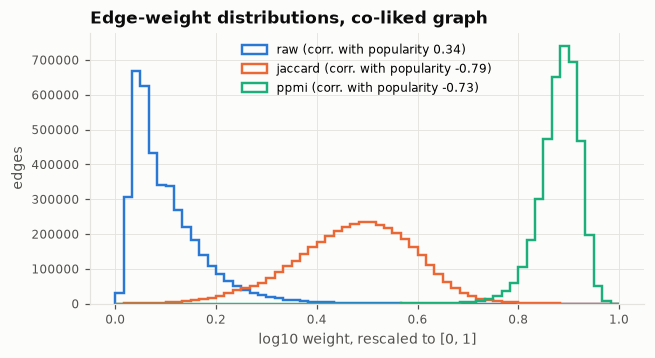

In [8]:
weighted = {}
for src, g in cographs.items():
    for scheme in WEIGHTINGS:
        with timed(f"4 weight {src} {scheme}"):
            weighted[(src, scheme)] = apply_weighting(g.weights, scheme, g.strength)
for name, G in external.items():
    weighted[(name, "raw")] = G

pop = book_popularity(bp)
title = lambda i: (meta.title.iloc[i] if pd.notna(meta.title.iloc[i]) else meta.item_id.iloc[i])[:55]
probe = int(np.argmax(pop))
rows = []
for scheme in WEIGHTINGS:
    row = weighted[("co-liked", scheme)][probe].tocoo()
    for rank, j in enumerate(row.col[np.argsort(-row.data)][:5], 1):
        rows.append({"weighting": scheme, "rank": rank, "neighbour": title(j), "readers": int(pop[j])})
print(f"Most-read book: {title(probe)} ({int(pop[probe])} readers)")
display(save_table(pd.DataFrame(rows).pivot(index="rank", columns="weighting", values="neighbour"), "example_neighbours"))

fig, ax = plt.subplots(figsize=(6.5, 3.2))
for scheme in WEIGHTINGS:
    W = weighted[("co-liked", scheme)]
    # Correlation between an edge's weight and the popularity of its endpoints: lower = less popularity bias.
    U = sp.triu(W, k=1).tocoo()
    r = np.corrcoef(np.log(U.data + 1e-12), np.log(pop[U.row] * pop[U.col]))[0, 1]
    vals = np.log10(U.data[U.data > 0])
    ax.hist((vals - vals.min()) / (vals.max() - vals.min()), bins=60, histtype="step", lw=1.6,
            color=P.WEIGHTING_COLOURS[scheme], label=f"{scheme} (corr. with popularity {r:.2f})")
ax.set_title("Edge-weight distributions, co-liked graph"); ax.set_xlabel("log10 weight, rescaled to [0, 1]"); ax.set_ylabel("edges")
ax.legend(); P.save(fig, FIGS, "04_weight_distributions"); plt.show()

## 5. Sparsification (implemented by us)

**Disparity filter** (Serrano, Boguna & Vespignani 2009): for node $i$ with degree $k_i$ and strength $s_i$, an edge's
p-value is $\alpha_{ij} = (1 - w_{ij}/s_i)^{k_i - 1}$ - the chance that a uniformly random split of $i$'s strength
gives an edge at least this heavy. Edges significant for at least one endpoint are kept. This keeps the locally
important links of weak (long-tail) books instead of applying one global threshold.

**Top-k** baseline: keep each book's $k$ heaviest edges.

A fixed $\alpha$ means very different things for different weightings (PPMI weights are almost uniform around each
node, so almost nothing is "significant"), so for the comparison we choose $\alpha$ per graph such that the
backbone has the **same number of edges as top-10**.

,graph,alpha,edges,edges_kept_pct,nodes_kept_pct,weight_kept_pct,giant_component_pct
0,co-reader raw,0.30,1810863,26.05,98.0,48.3,96.5
1,co-reader raw,0.10,322816,4.64,75.7,18.7,70.6
2,co-reader raw,0.05,157161,2.26,57.9,12.6,48.5
3,co-reader raw,0.01,49854,0.72,32.8,6.6,19.4
0,co-reader jaccard,0.30,2568213,36.94,99.7,62.8,98.2
1,co-reader jaccard,0.10,412923,5.94,97.0,18.5,94.8
2,co-reader jaccard,0.05,174501,2.51,87.8,10.3,80.1
3,co-reader jaccard,0.01,49489,0.71,55.3,4.5,23.9
0,co-reader ppmi,0.30,3038594,44.01,99.9,56.6,98.4
1,co-reader ppmi,0.10,33946,0.49,32.0,0.7,29.9


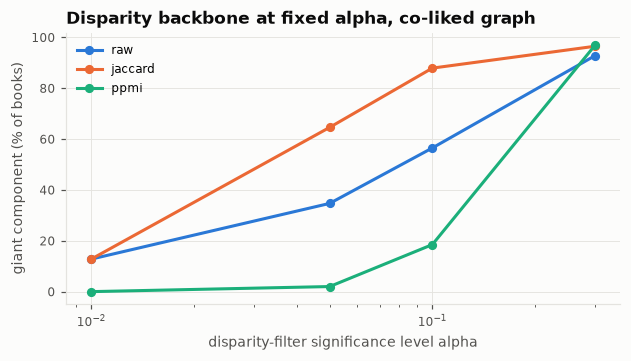

In [9]:
sweeps = []
for key, W in weighted.items():
    s = alpha_sweep(W, ALPHAS, name=f"{key[0]} {key[1]}")
    sweeps.append(s)
alpha_table = save_table(pd.concat(sweeps), "disparity_alpha_sweep")
display(alpha_table[["graph", "alpha", "edges", "edges_kept_pct", "nodes_kept_pct", "weight_kept_pct", "giant_component_pct"]])

fig, ax = plt.subplots(figsize=(6.5, 3.2))
for scheme in WEIGHTINGS:
    s = alpha_table[alpha_table.graph == f"co-liked {scheme}"]
    ax.plot(s.alpha, s.giant_component_pct, marker="o", color=P.WEIGHTING_COLOURS[scheme], label=scheme)
ax.set_xscale("log"); ax.set_xlabel("disparity-filter significance level alpha"); ax.set_ylabel("giant component (% of books)")
ax.set_title("Disparity backbone at fixed alpha, co-liked graph"); ax.legend()
P.save(fig, FIGS, "05_alpha_sweep"); plt.show()

In [10]:
variants, backbone_rows = {}, []
for key, W in weighted.items():
    with timed(f"5 sparsify {key[0]} {key[1]}"):
        K_ = top_k_neighbours(W, TOP_K)
        alpha = disparity_alpha_for_edges(W, K_.nnz // 2)
        D_ = disparity_filter(W, alpha)
    for method, G in [("disparity", D_), (f"top{TOP_K}", K_)]:
        variants[(*key, method)] = G
        backbone_rows.append({"source": key[0], "weighting": key[1], "sparsifier": method,
                              "alpha": alpha if method == "disparity" else np.nan,
                              **backbone_stats(W, G)})
    del K_, D_
backbones = save_table(pd.DataFrame(backbone_rows).drop(columns="graph"), "backbones")
display(backbones)
del weighted   # the dense-ish weighted graphs are no longer needed

[5 sparsify co-reader raw] 3.9s, heap peak 0.69 GB, process peak RSS 3.16 GB


[5 sparsify co-reader jaccard] 4.7s, heap peak 0.69 GB, process peak RSS 3.16 GB


[5 sparsify co-reader ppmi] 4.6s, heap peak 0.68 GB, process peak RSS 3.16 GB


[5 sparsify co-liked raw] 1.8s, heap peak 0.40 GB, process peak RSS 3.16 GB


[5 sparsify co-liked jaccard] 2.3s, heap peak 0.40 GB, process peak RSS 3.16 GB


[5 sparsify co-liked ppmi] 2.3s, heap peak 0.40 GB, process peak RSS 3.16 GB


,source,weighting,sparsifier,alpha,nodes_total,nodes_with_edges,nodes_kept_pct,edges,edges_kept_pct,weight_kept_pct,giant_component,giant_component_pct,mean_degree
0,co-reader,raw,disparity,0.1157,47937,37644,79.7,386234,5.56,20.6,36185,75.5,20.5
1,co-reader,raw,top10,NaN,47937,47226,100.0,386234,5.56,14.3,47199,98.5,16.4
2,co-reader,jaccard,disparity,0.0841,47937,45109,95.5,326156,4.69,15.7,44410,92.6,14.5
3,co-reader,jaccard,top10,NaN,47937,47226,100.0,326156,4.69,16.6,47210,98.5,13.8
4,co-reader,ppmi,disparity,0.1749,47937,41274,87.4,324106,4.69,6.7,41113,85.8,15.7
5,co-reader,ppmi,top10,NaN,47937,47226,100.0,324106,4.69,9.6,47210,98.5,13.7
6,co-liked,raw,disparity,0.1665,47937,37798,81.1,361217,8.93,27.0,36617,76.4,19.1
7,co-liked,raw,top10,NaN,47937,46625,100.0,361217,8.93,19.5,46566,97.1,15.5
8,co-liked,jaccard,disparity,0.1189,47937,44397,95.2,308733,7.64,22.5,43685,91.1,13.9
9,co-liked,jaccard,top10,NaN,47937,46625,100.0,308733,7.64,23.5,46566,97.1,13.2


## 6. Clustering

### 6.1 Louvain: resolution sweep and stability across seeds (main variant)

Louvain (igraph's C implementation of `community_multilevel`) maximises modularity with resolution $\gamma$:
larger $\gamma$ gives more, smaller communities. Each resolution is run with 5 seeds; stability is the mean pairwise
NMI / ARI between the seeds' partitions. Modularity is computed with **our** function.

[6 louvain sweep] 13.2s, heap peak 0.05 GB, process peak RSS 3.16 GB


,resolution,modularity,modularity_at_resolution,n_communities,n_communities_ge10,largest_pct,median_size,seed_stability_nmi,seed_stability_ari
0,0.5,0.8170,0.8781,388.4,52.2,31.82,2.0,0.8236,0.7872
1,1.0,0.8365,0.8365,409.8,67.8,14.94,2.0,0.8269,0.7226
2,2.0,0.8291,0.7845,450.2,109.2,8.64,2.2,0.8422,0.7395
3,5.0,0.7768,0.7044,545.2,198.4,3.66,3.0,0.8492,0.6538
4,10.0,0.7273,0.6381,675.6,329.4,2.10,7.9,0.8625,0.6509
5,20.0,0.6568,0.5695,904.6,556.8,1.36,27.8,0.8729,0.6232


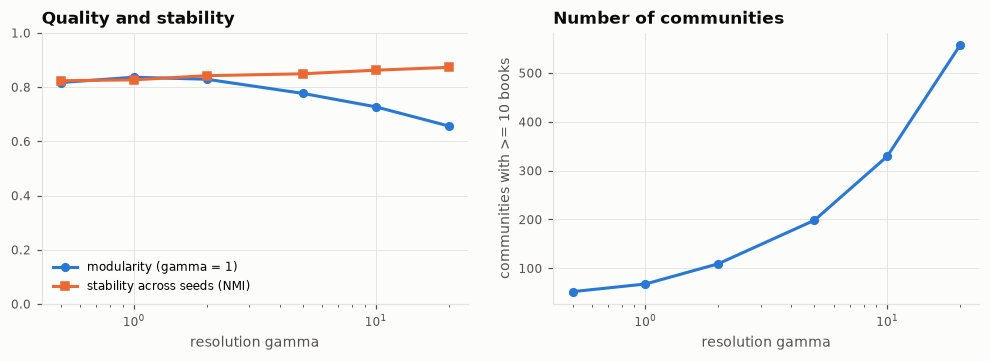

In [11]:
D = variants[MAIN]
with timed("6 louvain sweep"):
    sweep, partitions = resolution_sweep(D, RESOLUTIONS, SEEDS)
sweep_summary = save_table(summarise_sweep(sweep), "louvain_resolution_sweep")
display(sweep_summary)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].plot(sweep_summary.resolution, sweep_summary.modularity, marker="o", label="modularity (gamma = 1)")
axes[0].plot(sweep_summary.resolution, sweep_summary.seed_stability_nmi, marker="s", label="stability across seeds (NMI)")
axes[0].set_xscale("log"); axes[0].set_xlabel("resolution gamma"); axes[0].set_ylim(0, 1); axes[0].legend()
axes[0].set_title("Quality and stability")
axes[1].plot(sweep_summary.resolution, sweep_summary.n_communities_ge10, marker="o", color=P.PALETTE[0])
axes[1].set_xscale("log"); axes[1].set_xlabel("resolution gamma"); axes[1].set_ylabel("communities with >= 10 books")
axes[1].set_title("Number of communities")
P.save(fig, FIGS, "06_resolution_sweep"); plt.show()

### 6.2 Sanity checks: our modularity vs libraries; igraph vs networkx Louvain

In [12]:
lab_main = partitions[(1, 0)]
checks = {"modularity_ours": modularity(D, lab_main),
          "modularity_igraph": to_igraph(D).modularity(lab_main.tolist(), weights="weight"),
          "modularity_networkx": networkx_modularity(D, lab_main)}
with timed("6 networkx louvain"):
    lab_nx = louvain(D, 1.0, seed=0, backend="networkx")
from sklearn.metrics import normalized_mutual_info_score as nmi
has_edge = np.diff(D.indptr) > 0
checks.update({"networkx_louvain_modularity": modularity(D, lab_nx),
               "nmi_igraph_vs_networkx_partition": nmi(lab_main[has_edge], lab_nx[has_edge])})
display(pd.DataFrame([checks]).T.rename(columns={0: "value"}))
SUMMARY["modularity_checks"] = {k: float(v) for k, v in checks.items()}

[6 networkx louvain] 41.4s, heap peak 0.28 GB, process peak RSS 3.16 GB


,value
modularity_ours,0.8374
modularity_igraph,0.8374
modularity_networkx,0.8374
networkx_louvain_modularity,0.8353
nmi_igraph_vs_networkx_partition,0.8100


### 6.3 Spectral clustering (implemented by us)

Normalised spectral clustering (Ng, Jordan & Weiss): the $k$ eigenvectors of the normalised Laplacian
$L_{sym} = I - D^{-1/2} W D^{-1/2}$ with the smallest eigenvalues (scipy `eigsh` on $D^{-1/2} W D^{-1/2}$),
row-normalised, then k-means. It runs on the **giant component** of the main backbone (the Laplacian of a
disconnected graph has one zero eigenvalue per component). This is feasible at full size because the backbone is sparse.

[6 spectral embedding] 4.3s, heap peak 0.12 GB, process peak RSS 3.16 GB


[6 spectral k=20] 0.5s, heap peak 0.02 GB, process peak RSS 3.16 GB


[6 spectral k=40] 0.9s, heap peak 0.04 GB, process peak RSS 3.16 GB


[6 spectral k=60] 2.6s, heap peak 0.06 GB, process peak RSS 3.16 GB
giant component: 43685 books, 308244 edges


,method,k,modularity,nmi,nmi_random_baseline
0,Louvain (gamma=1),124,0.8364,0.2785,0.0354
1,spectral (ours),20,0.7123,0.2373,0.0148
2,spectral (ours),40,0.7512,0.2534,0.0253
3,spectral (ours),60,0.7358,0.2668,0.0321


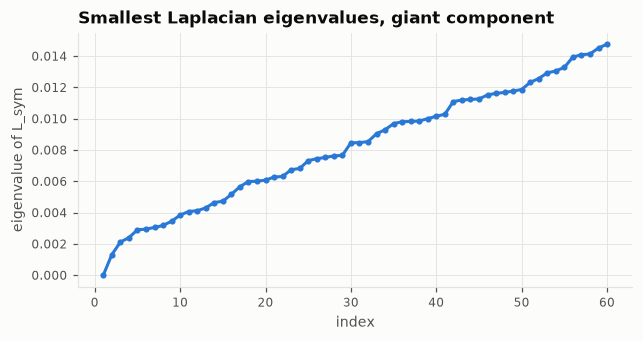

In [13]:
gc = giant_component(D)
Wg = D[gc][:, gc]
with timed("6 spectral embedding"):
    eigvals, emb = spectral_embedding(Wg, max(SPECTRAL_KS), seed=SEED)
meta_gc = meta.iloc[gc].reset_index(drop=True)
lab_gc = lab_main[gc]
rows = [{"method": "Louvain (gamma=1)", "k": len(np.unique(lab_gc)), "modularity": modularity(Wg, lab_gc),
         **{k: v for k, v in genre_nmi(lab_gc, meta_gc).items() if k in ("nmi", "nmi_random_baseline")}}]
for k in SPECTRAL_KS:
    with timed(f"6 spectral k={k}"):
        lab_sp = spectral_clustering(Wg, k, seed=SEED, embedding=emb)
    rows.append({"method": "spectral (ours)", "k": k, "modularity": modularity(Wg, lab_sp),
                 **{kk: v for kk, v in genre_nmi(lab_sp, meta_gc).items() if kk in ("nmi", "nmi_random_baseline")}})
spectral_table = save_table(pd.DataFrame(rows), "spectral_vs_louvain")
print(f"giant component: {len(gc)} books, {Wg.nnz // 2} edges")
display(spectral_table)

fig, ax = plt.subplots(figsize=(6.5, 3))
ax.plot(np.arange(1, len(eigvals) + 1), eigvals, marker="o", ms=3, color=P.PALETTE[0])
ax.set_xlabel("index"); ax.set_ylabel("eigenvalue of L_sym"); ax.set_title("Smallest Laplacian eigenvalues, giant component")
P.save(fig, FIGS, "06_spectral_eigenvalues"); plt.show()
SUMMARY["giant_component_books"] = int(len(gc))

### 6.4 Louvain on every graph variant

All graphs at $\gamma = 1$, seed 0. NMI is computed on the books that have a genre label (see decisions D6), with a
random-permutation baseline.

In [14]:
labels, rows = {}, []
for key, G in variants.items():
    with timed(f"6 louvain {' '.join(key)}"):
        lab = louvain(G, 1.0, seed=0)
    labels[key] = lab
    nodes = np.flatnonzero(np.diff(G.indptr) > 0)
    rows.append({"source": key[0], "weighting": key[1], "sparsifier": key[2], "modularity": modularity(G, lab),
                 **size_summary(lab, nodes), **genre_nmi(lab, meta, nodes)})
variant_table = save_table(pd.DataFrame(rows), "louvain_variants")
display(variant_table[["source", "weighting", "sparsifier", "modularity", "n_ge10", "largest_pct", "pct_nodes_in_ge10",
                       "nmi", "nmi_single_genre", "nmi_random_baseline", "ari"]])

[6 louvain co-reader raw disparity] 0.9s, heap peak 0.06 GB, process peak RSS 3.16 GB


[6 louvain co-reader raw top10] 0.9s, heap peak 0.06 GB, process peak RSS 3.16 GB


[6 louvain co-reader jaccard disparity] 0.8s, heap peak 0.05 GB, process peak RSS 3.16 GB


[6 louvain co-reader jaccard top10] 1.1s, heap peak 0.05 GB, process peak RSS 3.16 GB


[6 louvain co-reader ppmi disparity] 0.9s, heap peak 0.05 GB, process peak RSS 3.16 GB


[6 louvain co-reader ppmi top10] 1.7s, heap peak 0.05 GB, process peak RSS 3.16 GB


... (3 outputs left out)

[6 louvain co-liked jaccard top10] 1.1s, heap peak 0.05 GB, process peak RSS 3.16 GB


[6 louvain co-liked ppmi disparity] 0.8s, heap peak 0.05 GB, process peak RSS 3.16 GB


[6 louvain co-liked ppmi top10] 1.0s, heap peak 0.05 GB, process peak RSS 3.16 GB


,source,weighting,sparsifier,modularity,n_ge10,largest_pct,pct_nodes_in_ge10,nmi,nmi_single_genre,nmi_random_baseline,ari
0,co-reader,raw,disparity,0.7214,64,19.3,94.8,0.3047,0.2616,0.0796,0.1263
1,co-reader,raw,top10,0.7751,41,17.0,100.0,0.2850,0.2392,0.0207,0.1953
2,co-reader,jaccard,disparity,0.8449,72,15.2,98.0,0.2805,0.2693,0.0549,0.1163
3,co-reader,jaccard,top10,0.8124,55,14.9,100.0,0.2870,0.2714,0.0271,0.1351
4,co-reader,ppmi,disparity,0.5556,19,20.9,99.3,0.2198,0.2625,0.0258,0.2923
5,co-reader,ppmi,top10,0.6717,22,17.8,100.0,0.3051,0.2661,0.0162,0.2618
6,co-liked,raw,disparity,0.7419,54,26.8,95.6,0.3160,0.2831,0.0698,0.1376
7,co-liked,raw,top10,0.7755,41,21.5,99.9,0.2688,0.2651,0.0215,0.1325
8,co-liked,jaccard,disparity,0.8374,67,15.3,97.9,0.2905,0.2749,0.0582,0.1467
9,co-liked,jaccard,top10,0.8063,51,15.1,99.9,0.2771,0.2659,0.0281,0.1201


## 7. Community evaluation (main variant)

Size distribution, and the genre make-up of each community. A community is **mixed** when its second most common
genre still covers >= 25% of its genre-labelled books - reader communities that cut across Amazon's genre tree.

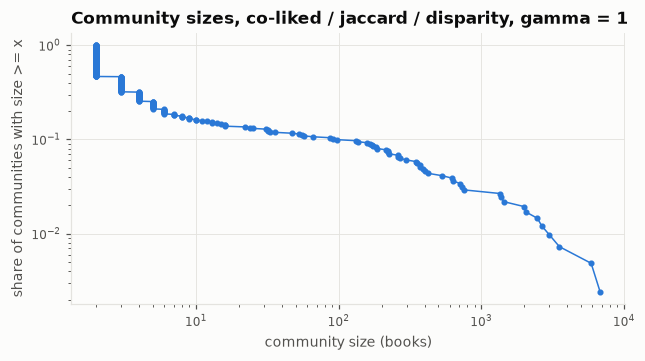

39 communities with >= 15 labelled books; 12 are mixed


,community,size,labelled,genre_1,share_1,genre_2,share_2,entropy,mixed,top_titles
0,0,6800,70,History,0.17,Science Fiction & Fantasy,0.17,0.718,False,The Foreign Correspondent: A Novel | Disgrace ...
1,8,5888,80,"Mystery, Thriller & Suspense",0.36,Literature & Fiction,0.21,0.643,False,The Lake Shore Limited | Cartwheel: A Novel | ...
2,10,3530,369,Romance,0.67,Science Fiction & Fantasy,0.21,0.307,False,Confessions of an Improper Bride (A Donovan No...
3,3,3002,101,"Mystery, Thriller & Suspense",0.64,Literature & Fiction,0.17,0.323,False,Company Man | Power Play | Ties That Bind (Mar...
4,56,2650,84,Christian Books & Bibles,0.65,"Mystery, Thriller & Suspense",0.08,0.405,False,That Certain Summer: A Novel | With Every Lett...
5,168,2475,840,Romance,0.63,Literature & Fiction,0.17,0.332,False,Real (The REAL series) | Forever Too Far: A Ro...
6,17,2057,115,Teen & Young Adult,0.62,Children's Books,0.13,0.394,False,Siren (Siren Novels) | Shadow Hills | Fixing D...
7,39,1990,1018,Romance,0.73,Literature & Fiction,0.08,0.330,False,Badass: Hell Yeah (Hell Yeah! Book 5) | Royal ...
8,11,1444,31,Children's Books,0.55,Science Fiction & Fantasy,0.10,0.464,False,The Sandman: Season of Mists - Book IV (Sandma...
9,63,1367,396,"Mystery, Thriller & Suspense",0.71,Literature & Fiction,0.07,0.369,False,Rage (Faces of Evil) | Revenge: The Faces of E...


,community,size,labelled,genre_1,share_1,genre_2,share_2,entropy,mixed,top_titles
13,494,713,205,Romance,0.27,Teen & Young Adult,0.27,0.509,True,Shadows &amp; Voices; A Holly Silverstone Adve...
32,419,184,97,Science Fiction & Fantasy,0.35,Romance,0.26,0.474,True,The Witch and the Gentleman | A Charming Crime...
34,437,132,29,Romance,0.38,Christian Books & Bibles,0.31,0.443,True,Longing for Home: A Proper Romance | A Timeles...
19,463,393,173,Teen & Young Adult,0.41,Romance,0.29,0.424,True,The Warlock King (Kings) | Her Guardian Angel:...
20,132,374,92,Literature & Fiction,0.40,Science Fiction & Fantasy,0.33,0.413,True,A New World: Return (Volume 2) | A New World: ...
33,364,166,63,Science Fiction & Fantasy,0.43,Teen & Young Adult,0.37,0.353,True,"Kindred (Book 2, The Watcher Chronicles) | Obl..."
28,103,223,56,"Mystery, Thriller & Suspense",0.46,Science Fiction & Fantasy,0.38,0.351,True,299 Days: The Stronghold (Volume 4) | 299 Days...
36,727,87,47,"Mystery, Thriller & Suspense",0.43,Romance,0.40,0.347,True,Big Girls Do It Married | Rock Stars Do It | S...
29,29,222,35,Romance,0.46,"Mystery, Thriller & Suspense",0.34,0.345,True,When Love Awaits (Avon Historical Romance) | L...
23,35,349,115,Romance,0.58,Literature & Fiction,0.30,0.324,True,Dutch and Gina: After the Fall (Volume 4) | Mo...


In [15]:
nodes_main = np.flatnonzero(np.diff(D.indptr) > 0)
sizes = community_sizes(lab_main, nodes_main).to_numpy()
fig, ax = plt.subplots(figsize=(6.5, 3.2))
x = np.sort(sizes); ax.loglog(x, 1 - np.arange(len(x)) / len(x), marker="o", ms=3, lw=1, color=P.PALETTE[0])
ax.set_xlabel("community size (books)"); ax.set_ylabel("share of communities with size >= x")
ax.set_title(f"Community sizes, {' / '.join(MAIN)}, gamma = 1")
P.save(fig, FIGS, "07_community_sizes"); plt.show()

genre_table = save_table(community_genre_table(lab_main, meta, D, min_labelled=15), "community_genres")
print(f"{len(genre_table)} communities with >= 15 labelled books; {int(genre_table.mixed.sum())} are mixed")
display(genre_table.head(15))
display(genre_table[genre_table.mixed].sort_values("entropy", ascending=False).head(12))
SUMMARY["main_partition"] = {**size_summary(lab_main, nodes_main), **genre_nmi(lab_main, meta, nodes_main),
                             "modularity": float(modularity(D, lab_main)),
                             "mixed_communities": int(genre_table.mixed.sum()), "communities_ge15_labelled": len(genre_table)}

## 8. Community-based recommender

For each test user we recommend 10 books they had not read before the cut-off and evaluate against the books they
**liked in Jan-Jul 2014** (only books that exist in the training graph; brand-new books are the cold-start part).
The same test users and items are used for every variant.

Recommenders:
- **most popular** - baseline
- **item-kNN (co-reader)** - "readers also bought": sum of raw co-reader counts with the user's liked books. This is
  *purchase overlap alone*, the baseline the project question is about
- **community** - books from the communities of the user's liked books. The within-community ranking is a design
  choice: weighted degree inside the community (`strength`), popularity, or `personal` (backbone links to the
  user's own liked books, restricted to the same community)
- **hybrid** - $(1-\lambda)\,$item-kNN $+ \lambda\,$community (both row-normalised): do communities add signal to overlap?

**Popularity groups:** books sorted by training readers and cut into head / mid / tail so that each holds one third
of all training interactions. Per group, only the user's relevant books in that group count.

**No tuning on the test set:** 20% of the test users are a validation set used to choose the resolution, the ranking
and $\lambda$ on the main variant; all reported numbers are on the remaining 80%.

In [16]:
with timed("8 test set"):
    test_all = make_test_set(test, bp)
    val, final = split_test_users(test_all, val_frac=0.2, seed=SEED)
groups = popularity_groups(pop)
S = series_onehot(meta["series"])
group_table = pd.DataFrame({
    "group": ["head", "mid", "tail"],
    "books": [int((groups == g).sum()) for g in ("head", "mid", "tail")],
    "min_readers": [int(pop[groups == g].min()) for g in ("head", "mid", "tail")],
    "test_items": [int(test_all.relevant[:, np.flatnonzero(groups == g)].nnz) for g in ("head", "mid", "tail")],
})
display(save_table(group_table, "popularity_groups"))
print(f"test users: {len(test_all.users)} (validation {len(val.users)}, final {len(final.users)}); "
      f"relevant items: {test_all.relevant.nnz}")
SUMMARY["test"] = {"users": int(len(test_all.users)), "val_users": int(len(val.users)), "final_users": int(len(final.users)),
                   "relevant": int(test_all.relevant.nnz), "groups": group_table.to_dict("records")}

knn = ItemKNNRecommender(cographs["co-reader"].shared, pop, name="item-kNN (co-reader)")
popular = PopularityRecommender(pop)

[8 test set] 1.2s, heap peak 0.07 GB, process peak RSS 3.16 GB


,group,books,min_readers,test_items
0,head,3484,81,77445
1,mid,12443,30,72095
2,tail,32010,1,111565


test users: 74715 (validation 14873, final 59842); relevant items: 261105


In [17]:
def headline(rec, ts, series=None):
    r = evaluate(rec, bp, ts, groups, series, k=K)
    return r

val_rows = []
def val_eval(rec, **info):
    r = headline(rec, val).set_index("group")
    val_rows.append({**info, "recall@10": r.loc["all", "recall@10"], "ndcg@10": r.loc["all", "ndcg@10"],
                     "recall_mid": r.loc["mid", "recall@10"], "recall_tail": r.loc["tail", "recall@10"],
                     "coverage": r.loc["all", "coverage"]})

with timed("8 validation grid"):
    val_eval(knn, model="item-kNN")
    for res in [1, 5, 20]:
        lab = partitions[(res, 0)] if (res, 0) in partitions else louvain(D, res, seed=0)
        for within in ["strength", "popularity", "personal"]:
            val_eval(CommunityRecommender(lab, D, pop, within=within), model="community", resolution=res, within=within)
val_grid = save_table(pd.DataFrame(val_rows), "validation_grid")
display(val_grid)

best = val_grid[val_grid.model == "community"].sort_values("recall@10", ascending=False).iloc[0]
BEST_RES, BEST_WITHIN = float(best.resolution), best.within
print(f"chosen on validation: resolution {BEST_RES}, within-community ranking '{BEST_WITHIN}'")

[8 validation grid] 56.0s, heap peak 0.99 GB, process peak RSS 3.16 GB


,model,recall@10,ndcg@10,recall_mid,recall_tail,coverage,resolution,within
0,item-kNN,0.0393,0.0269,0.0230,0.0103,0.3029,NaN,NaN
1,community,0.0034,0.0026,0.0033,0.0024,0.0255,1.0,strength
2,community,0.0180,0.0117,0.0028,0.0006,0.0251,1.0,popularity
3,community,0.0430,0.0307,0.0426,0.0286,0.6307,1.0,personal
4,community,0.0074,0.0048,0.0078,0.0059,0.0641,5.0,strength
5,community,0.0226,0.0152,0.0071,0.0007,0.0603,5.0,popularity
6,community,0.0430,0.0305,0.0432,0.0294,0.6194,5.0,personal
7,community,0.0129,0.0085,0.0124,0.0099,0.1544,20.0,strength
8,community,0.0213,0.0147,0.0133,0.0013,0.1468,20.0,popularity
9,community,0.0423,0.0303,0.0436,0.0289,0.6236,20.0,personal


chosen on validation: resolution 1.0, within-community ranking 'personal'


[8 validation lambda] 52.9s, heap peak 1.18 GB, process peak RSS 3.16 GB


,lambda,recall_all,recall_head,recall_mid,recall_tail,ndcg@10
0,0.0,0.0393,0.0799,0.0232,0.0102,0.0270
1,0.1,0.0413,0.0816,0.0257,0.0112,0.0280
2,0.2,0.0431,0.0819,0.0288,0.0133,0.0292
3,0.3,0.0434,0.0788,0.0309,0.0159,0.0298
4,0.5,0.0451,0.0722,0.0363,0.0211,0.0313
5,0.7,0.0451,0.0633,0.0405,0.0259,0.0317
6,1.0,0.0430,0.0521,0.0426,0.0286,0.0307


chosen lambda: 0.5


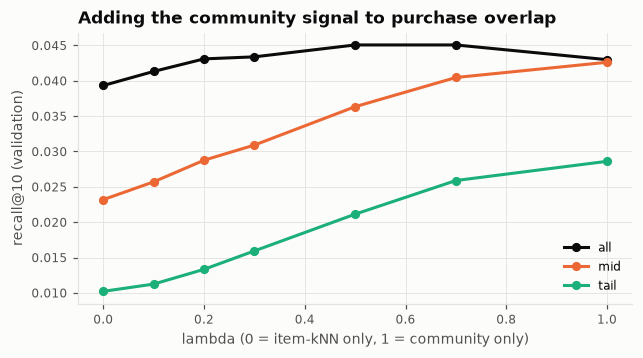

In [18]:
lab_best = partitions.get((BEST_RES, 0), None)
if lab_best is None:
    lab_best = louvain(D, BEST_RES, seed=0)
comm_best = CommunityRecommender(lab_best, D, pop, within=BEST_WITHIN)
lam_rows = []
with timed("8 validation lambda"):
    for lam in [0.0, 0.1, 0.2, 0.3, 0.5, 0.7, 1.0]:
        r = headline(HybridRecommender(knn, comm_best, lam), val).set_index("group")
        lam_rows.append({"lambda": lam, **{f"recall_{g}": r.loc[g, "recall@10"] for g in ["all", "head", "mid", "tail"]},
                         "ndcg@10": r.loc["all", "ndcg@10"]})
lam_table = save_table(pd.DataFrame(lam_rows), "validation_lambda")
display(lam_table)
BEST_LAM = float(lam_table.loc[lam_table.recall_all.idxmax(), "lambda"])
print("chosen lambda:", BEST_LAM)

fig, ax = plt.subplots(figsize=(6.5, 3.2))
for g, col in [("all", P.TEXT), ("mid", P.GROUP_COLOURS["mid"]), ("tail", P.GROUP_COLOURS["tail"])]:
    ax.plot(lam_table["lambda"], lam_table[f"recall_{g}"], marker="o", color=col, label=g)
ax.set_xlabel("lambda (0 = item-kNN only, 1 = community only)"); ax.set_ylabel("recall@10 (validation)")
ax.set_title("Adding the community signal to purchase overlap"); ax.legend()
P.save(fig, FIGS, "08_hybrid_lambda"); plt.show()
SUMMARY["chosen"] = {"resolution": BEST_RES, "within": BEST_WITHIN, "lambda": BEST_LAM}

### 8.1 Final evaluation on the held-out users

Every graph variant is clustered with the chosen resolution and evaluated with the chosen ranking, as a pure
community recommender and as a hybrid with item-kNN. "No same-series" removes books from series the user already
read (series continuations are easy hits that inflate scores; this replaces the same-author check because the
metadata has no author).

In [19]:
results, per_user = [], {}
def final_eval(rec, **info):
    r, pu = evaluate(rec, bp, final, groups, S, k=K, return_per_user=True)
    per_user[rec.name] = pu
    for k_, v in info.items():
        r[k_] = v
    results.append(r)

with timed("8 final baselines"):
    final_eval(popular, family="baseline", source="-", weighting="-", sparsifier="-")
    final_eval(knn, family="baseline", source="co-reader", weighting="raw", sparsifier="none")
for key, G in variants.items():
    with timed(f"8 final {' '.join(key)}"):
        lab = louvain(G, BEST_RES, seed=0) if key != MAIN else lab_best
        comm = CommunityRecommender(lab, G, pop, within=BEST_WITHIN, name=f"community {' / '.join(key)}")
        info = dict(source=key[0], weighting=key[1], sparsifier=key[2])
        final_eval(comm, family="community", **info)
        final_eval(HybridRecommender(knn, comm, BEST_LAM, name=f"hybrid {' / '.join(key)}"), family="hybrid", **info)
        final_eval(ItemKNNRecommender(G, pop, name=f"backbone-kNN {' / '.join(key)}"), family="backbone-kNN", **info)
final_results = save_table(pd.concat(results, ignore_index=True), "recommender_results")

[8 final baselines] 90.6s, heap peak 1.01 GB, process peak RSS 3.16 GB


[8 final co-reader raw disparity] 149.3s, heap peak 1.21 GB, process peak RSS 3.16 GB


[8 final co-reader raw top10] 143.5s, heap peak 1.21 GB, process peak RSS 3.16 GB


[8 final co-reader jaccard disparity] 147.3s, heap peak 1.21 GB, process peak RSS 3.16 GB


[8 final co-reader jaccard top10] 145.6s, heap peak 1.21 GB, process peak RSS 3.16 GB


[8 final co-reader ppmi disparity] 138.0s, heap peak 1.21 GB, process peak RSS 3.16 GB


... (3 outputs left out)

[8 final co-liked jaccard disparity] 137.4s, heap peak 1.21 GB, process peak RSS 3.16 GB


[8 final co-liked jaccard top10] 148.7s, heap peak 1.21 GB, process peak RSS 3.16 GB


[8 final co-liked ppmi disparity] 149.3s, heap peak 1.21 GB, process peak RSS 3.16 GB


[8 final co-liked ppmi top10] 147.1s, heap peak 1.21 GB, process peak RSS 3.16 GB


=== recall@10, all books ===


group                                                         all    head     mid    tail  coverage
family       recommender                                                                           
hybrid       hybrid co-liked / jaccard / top10             0.0456  0.0655  0.0394  0.0253    0.7846
             hybrid co-reader / jaccard / top10            0.0453  0.0655  0.0392  0.0251    0.7938
community    community co-reader / jaccard / top10         0.0453  0.0451  0.0440  0.0373    0.8879
backbone-kNN backbone-kNN co-reader / jaccard / top10      0.0453  0.0441  0.0439  0.0379    0.9030
community    community co-liked / jaccard / top10          0.0449  0.0439  0.0440  0.0370    0.8746
             community co-liked / raw / top10              0.0449  0.0791  0.0345  0.0162    0.5952
hybrid       hybrid co-liked / jaccard / disparity         0.0449  0.0682  0.0383  0.0224    0.7431
backbone-kNN backbone-kNN co-liked / jaccard / top10       0.0448  0.0432  0.0438  0.0373    0.8870
             backbone-kNN co-liked / raw / top10           0.0446  0.0800  0.0334  0.0154    0.5668
hybrid       hybrid co-reader / jaccard / disparity        0.0444  0.0681  0.0379  0.0221    0.7390
community    community co-reader / raw / top10             0.0443  0.0787  0.0334  0.0156    0.5963
backbone-kNN backbone-kNN co-reader / raw / top10          0.0437  0.0794  0.0319  0.0147    0.5603
community    community co-liked / jaccard / disparity      0.0436  0.0489  0.0431  0.0309    0.8261
backbone-kNN backbone-kNN co-liked / jaccard / disparity   0.0435  0.0485  0.0430  0.0310    0.8422
             backbone-kNN co-reader / jaccard / disparity  0.0433  0.0495  0.0430  0.0306    0.8480
community    community co-reader / jaccard / disparity     0.0433  0.0493  0.0433  0.0307    0.8301
hybrid       hybrid co-liked / raw / top10                 0.0429  0.0796  0.0310  0.0138    0.5687
             hybrid co-reader / raw / top10                0.0428  0.0798  0.0303  0.0134    0.5685
community    community co-liked / raw / disparity          0.0420  0.0787  0.0308  0.0121    0.4797
hybrid       hybrid co-liked / raw / disparity             0.0420  0.0796  0.0296  0.0124    0.5110
backbone-kNN backbone-kNN co-liked / raw / disparity       0.0418  0.0800  0.0295  0.0114    0.4736
hybrid       hybrid co-reader / raw / disparity            0.0406  0.0778  0.0287  0.0116    0.5004
backbone-kNN backbone-kNN co-reader / raw / disparity      0.0405  0.0790  0.0275  0.0106    0.4532
community    community co-reader / raw / disparity         0.0404  0.0766  0.0293  0.0113    0.4623
baseline     item-kNN (co-reader)                          0.0382  0.0759  0.0254  0.0101    0.4883
hybrid       hybrid co-reader / ppmi / top10               0.0374  0.0364  0.0311  0.0369    0.8771
             hybrid co-liked / ppmi / top10                0.0367  0.0366  0.0327  0.0346    0.8931
             hybrid co-liked / ppmi / disparity            0.0351  0.0520  0.0296  0.0199    0.7888
             hybrid co-reader / ppmi / disparity           0.0344  0.0508  0.0287  0.0204    0.7674
community    community co-reader / ppmi / top10            0.0276  0.0063  0.0218  0.0436    0.8188
             community co-liked / ppmi / top10             0.0272  0.0066  0.0229  0.0417    0.8574
backbone-kNN backbone-kNN co-liked / ppmi / top10          0.0266  0.0050  0.0225  0.0420    0.8453
             backbone-kNN co-reader / ppmi / top10         0.0266  0.0046  0.0208  0.0436    0.7948
community    community co-liked / ppmi / disparity         0.0191  0.0151  0.0185  0.0201    0.7224
backbone-kNN backbone-kNN co-liked / ppmi / disparity      0.0189  0.0144  0.0180  0.0207    0.7210
community    community co-reader / ppmi / disparity        0.0185  0.0143  0.0173  0.0202    0.6899
backbone-kNN backbone-kNN co-reader / ppmi / disparity     0.0183  0.0139  0.0168  0.0206    0.6886
baseline     most popular                                  0.0075  0.0207  0.0000  0.0000    0.0004

=== recall@10, no same-series ===


group                                                         all    head     mid    tail  coverage
family       recommender                                                                           
community    community co-liked / raw / top10              0.0419  0.0751  0.0310  0.0146    0.5928
hybrid       hybrid co-liked / jaccard / top10             0.0417  0.0613  0.0345  0.0228    0.7781
backbone-kNN backbone-kNN co-liked / raw / top10           0.0414  0.0758  0.0296  0.0139    0.5647
hybrid       hybrid co-reader / jaccard / top10            0.0413  0.0612  0.0342  0.0225    0.7882
community    community co-reader / raw / top10             0.0411  0.0748  0.0290  0.0143    0.5927
hybrid       hybrid co-liked / jaccard / disparity         0.0410  0.0644  0.0336  0.0198    0.7323
             hybrid co-reader / jaccard / disparity        0.0406  0.0639  0.0332  0.0198    0.7285
backbone-kNN backbone-kNN co-reader / raw / top10          0.0405  0.0753  0.0277  0.0134    0.5573
community    community co-reader / jaccard / top10         0.0405  0.0397  0.0391  0.0340    0.8890
backbone-kNN backbone-kNN co-reader / jaccard / top10      0.0404  0.0387  0.0390  0.0346    0.9065
hybrid       hybrid co-liked / raw / top10                 0.0401  0.0761  0.0274  0.0125    0.5594
community    community co-liked / jaccard / top10          0.0400  0.0385  0.0390  0.0337    0.8770
backbone-kNN backbone-kNN co-liked / jaccard / top10       0.0398  0.0378  0.0389  0.0340    0.8913
hybrid       hybrid co-reader / raw / top10                0.0396  0.0756  0.0265  0.0119    0.5596
             hybrid co-liked / raw / disparity             0.0390  0.0757  0.0260  0.0111    0.4954
community    community co-liked / raw / disparity          0.0388  0.0744  0.0270  0.0106    0.4639
backbone-kNN backbone-kNN co-reader / jaccard / disparity  0.0387  0.0449  0.0382  0.0273    0.8432
             backbone-kNN co-liked / raw / disparity       0.0387  0.0763  0.0257  0.0099    0.4575
community    community co-reader / jaccard / disparity     0.0387  0.0448  0.0383  0.0273    0.8241
             community co-liked / jaccard / disparity      0.0386  0.0441  0.0379  0.0272    0.8207
backbone-kNN backbone-kNN co-liked / jaccard / disparity   0.0385  0.0438  0.0377  0.0274    0.8376
hybrid       hybrid co-reader / raw / disparity            0.0377  0.0736  0.0250  0.0103    0.4840
backbone-kNN backbone-kNN co-reader / raw / disparity      0.0373  0.0748  0.0238  0.0090    0.4338
community    community co-reader / raw / disparity         0.0372  0.0724  0.0254  0.0097    0.4433
baseline     item-kNN (co-reader)                          0.0353  0.0720  0.0219  0.0089    0.4727
hybrid       hybrid co-reader / ppmi / top10               0.0334  0.0326  0.0264  0.0337    0.8722
             hybrid co-liked / ppmi / top10                0.0325  0.0326  0.0279  0.0311    0.8892
             hybrid co-liked / ppmi / disparity            0.0311  0.0466  0.0253  0.0181    0.7857
             hybrid co-reader / ppmi / disparity           0.0302  0.0449  0.0245  0.0183    0.7637
community    community co-reader / ppmi / top10            0.0249  0.0057  0.0184  0.0399    0.8128
             community co-liked / ppmi / top10             0.0242  0.0059  0.0193  0.0379    0.8522
backbone-kNN backbone-kNN co-reader / ppmi / top10         0.0239  0.0039  0.0178  0.0399    0.7877
             backbone-kNN co-liked / ppmi / top10          0.0239  0.0045  0.0192  0.0382    0.8404
community    community co-liked / ppmi / disparity         0.0166  0.0137  0.0149  0.0181    0.7179
backbone-kNN backbone-kNN co-liked / ppmi / disparity      0.0166  0.0132  0.0146  0.0187    0.7168
community    community co-reader / ppmi / disparity        0.0163  0.0132  0.0138  0.0183    0.6849
backbone-kNN backbone-kNN co-reader / ppmi / disparity     0.0161  0.0127  0.0135  0.0188    0.6844
baseline     most popular                                  0.0077  0.0210  0.0000  0.0000    0.0004

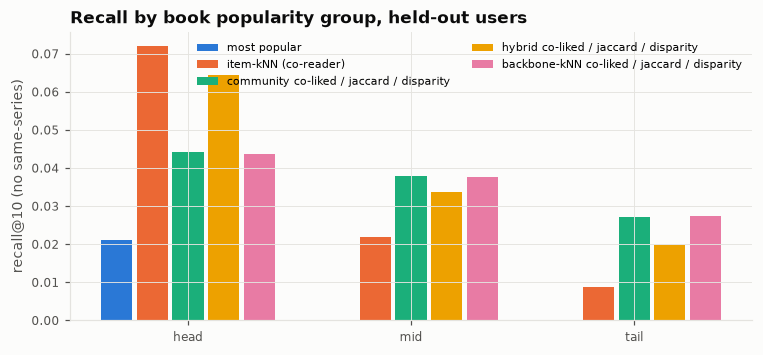

In [20]:
def wide(df, setting, metric="recall@10"):
    t = df[df.setting == setting].pivot_table(index=["family", "recommender"], columns="group", values=metric)
    cov = df[(df.setting == setting) & (df.group == "all")].set_index(["family", "recommender"])["coverage"]
    return t[["all", "head", "mid", "tail"]].assign(coverage=cov).sort_values("all", ascending=False)

for setting in ["all books", "no same-series"]:
    for metric in ["recall@10", "ndcg@10", "hit@10"]:
        t = wide(final_results, setting, metric)
        save_table(t.reset_index(), f"final_{metric.replace('@', '')}_{setting.replace(' ', '_')}")
        if metric == "recall@10":
            print(f"=== {metric}, {setting} ===")
            display(t.round(4))

main_name = " / ".join(MAIN)
key_models = ["most popular", "item-kNN (co-reader)", f"community {main_name}", f"hybrid {main_name}", f"backbone-kNN {main_name}"]
t = final_results[(final_results.setting == "no same-series") & final_results.recommender.isin(key_models) & (final_results.group != "all")]
fig, ax = plt.subplots(figsize=(8, 3.4))
width = 0.16
for i, m in enumerate(key_models):
    vals = t[t.recommender == m].set_index("group").reindex(["head", "mid", "tail"])["recall@10"]
    ax.bar(np.arange(3) + (i - 2) * width, vals.values, width=width - 0.02, color=P.PALETTE[i], label=m)
ax.set_xticks(range(3), ["head", "mid", "tail"]); ax.set_ylabel("recall@10 (no same-series)")
ax.set_title("Recall by book popularity group, held-out users"); ax.legend(fontsize=7, ncol=2)
P.save(fig, FIGS, "08_recall_by_group"); plt.show()

hl = final_results[(final_results.group == "all")].set_index(["setting", "recommender"])
SUMMARY["final_headline"] = {f"{s} | {m}": {k_: float(hl.loc[(s, m), k_]) for k_ in ["recall@10", "ndcg@10", "hit@10", "coverage"]}
                             for s in ["all books", "no same-series"] for m in key_models if (s, m) in hl.index}

### 8.2 Are the differences significant?

Paired bootstrap over the held-out users (2,000 resamples, 95% CI) of the per-user recall@10, without same-series
books. The key comparison for the role of clustering is **community vs backbone-kNN on the same graph**: both use the
same weighted backbone, the only difference is that the community recommender restricts candidates to the user's
communities.

In [21]:
comparisons = [(f"community {main_name}", "item-kNN (co-reader)"),
               (f"hybrid {main_name}", "item-kNN (co-reader)"),
               (f"community {main_name}", f"backbone-kNN {main_name}"),
               (f"backbone-kNN {main_name}", "item-kNN (co-reader)"),
               ("item-kNN (co-reader)", "most popular")]
rows = []
for a, b in comparisons:
    for g in ["all", "head", "mid", "tail"]:
        key = ("no same-series", g)
        rows.append({"a": a, "b": b, "group": g,
                     **paired_bootstrap(per_user[a][key]["recall"], per_user[b][key]["recall"], seed=SEED)})
significance = save_table(pd.DataFrame(rows), "significance_recall")
display(significance.round(4))
SUMMARY["significance"] = significance.to_dict("records")

,a,b,group,users,mean_a,mean_b,diff,ci_low,ci_high,relative_pct,significant
0,community co-liked / jaccard / disparity,item-kNN (co-reader),all,59392,0.0386,0.0353,0.0033,0.0022,0.0045,9.3459,True
1,community co-liked / jaccard / disparity,item-kNN (co-reader),head,31251,0.0441,0.0720,-0.0279,-0.0301,-0.0258,-38.7300,True
2,community co-liked / jaccard / disparity,item-kNN (co-reader),mid,29843,0.0379,0.0219,0.0160,0.0144,0.0177,72.8226,True
3,community co-liked / jaccard / disparity,item-kNN (co-reader),tail,37040,0.0272,0.0089,0.0183,0.0171,0.0197,207.0573,True
4,hybrid co-liked / jaccard / disparity,item-kNN (co-reader),all,59392,0.0410,0.0353,0.0057,0.0048,0.0066,16.1307,True
5,hybrid co-liked / jaccard / disparity,item-kNN (co-reader),head,31251,0.0644,0.0720,-0.0076,-0.0093,-0.0061,-10.5799,True
6,hybrid co-liked / jaccard / disparity,item-kNN (co-reader),mid,29843,0.0336,0.0219,0.0117,0.0105,0.0130,53.1881,True
7,hybrid co-liked / jaccard / disparity,item-kNN (co-reader),tail,37040,0.0198,0.0089,0.0110,0.0100,0.0119,123.7933,True
8,community co-liked / jaccard / disparity,backbone-kNN co-liked / jaccard / disparity,all,59392,0.0386,0.0385,0.0001,-0.0003,0.0004,0.1429,False
9,community co-liked / jaccard / disparity,backbone-kNN co-liked / jaccard / disparity,head,31251,0.0441,0.0438,0.0003,-0.0005,0.0011,0.7457,False


## 9. Runtime and memory

In [22]:
rt = save_table(runtime_table(), "runtimes")
display(rt)
print(f"process peak RSS: {process_peak_rss_gb():.2f} GB")
SUMMARY["peak_rss_gb"] = round(process_peak_rss_gb(), 2)
SUMMARY["total_runtime_min"] = round(rt.seconds.sum() / 60, 1)
(RESULTS / "summary.json").write_text(json.dumps(SUMMARY, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)))
print("saved", RESULTS / "summary.json")

,step,seconds,heap_peak_gb,process_peak_rss_gb
0,1 preprocessing,0.12,0.001,0.51
1,2 bipartite matrix,4.97,0.198,0.91
2,3 graph co-reader,6.18,0.943,2.86
3,3 graph co-liked,3.92,0.565,2.96
4,4 weight co-reader raw,0.01,0.111,3.10
5,4 weight co-reader jaccard,0.29,0.564,3.10
6,4 weight co-reader ppmi,0.36,0.617,3.16
7,4 weight co-liked raw,0.00,0.065,3.16
8,4 weight co-liked jaccard,0.15,0.328,3.16
9,4 weight co-liked ppmi,0.18,0.360,3.16


process peak RSS: 3.16 GB
saved /Users/vishwaa/Documents/DTU/computational Tools for data science/02807_computational_tools_ds/docs/results/full_fromall_cut2014-01-01_u5b15/summary.json


## 10. Summary

The numbers in this notebook are collected in `docs/graph_clustering_results.md` (written from the full-data run).
Course methods: Louvain, spectral clustering, modularity. Outside the course: PPMI, Jaccard weighting of a
projected bipartite graph, the disparity-filter backbone.